### Demo of SNPmanifold

In [ ]:
# If you want to use cuda

import torch
torch.set_default_device('cuda')
torch.cuda.set_device('cuda:0')

Matplotlib created a temporary cache directory at /tmp/matplotlib-jvzsl017 because the default path (/ssd2/users/kevin/.cache/matplotlib) is not a writable directory; it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.
/nobackup2/users/kevin/conda_envs/test_SNPmanifold_ST/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Start loading raw data.
Finish loading raw data.
Start filtering low-quality cells and SNPs.


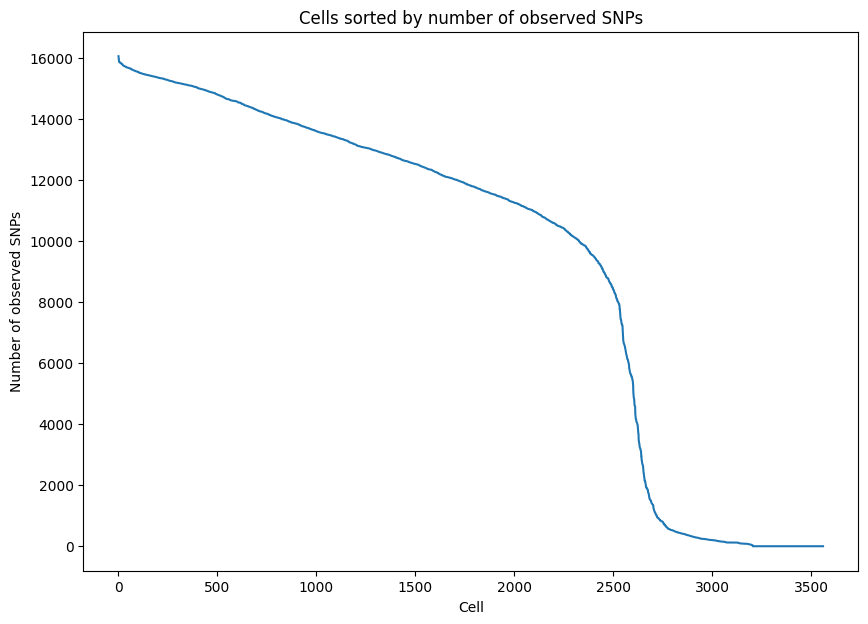

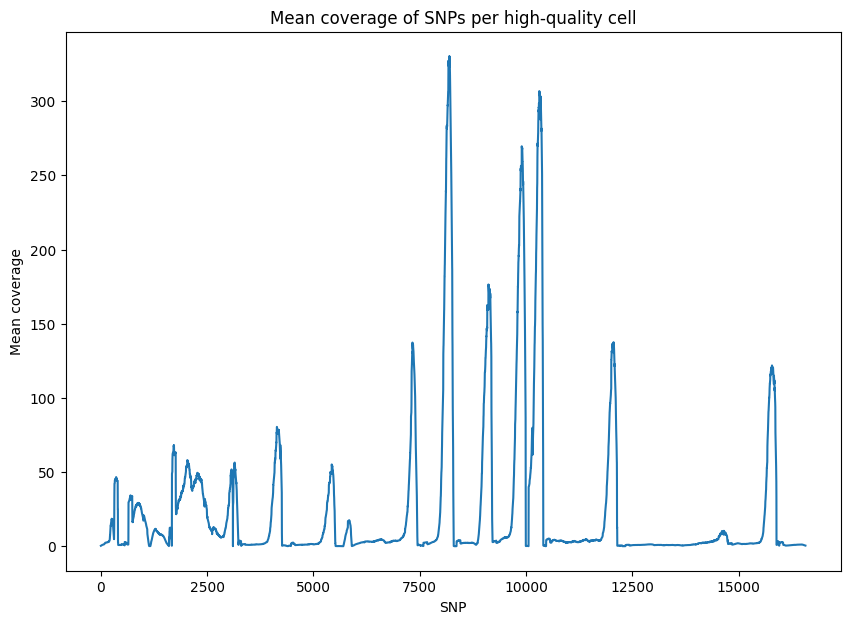

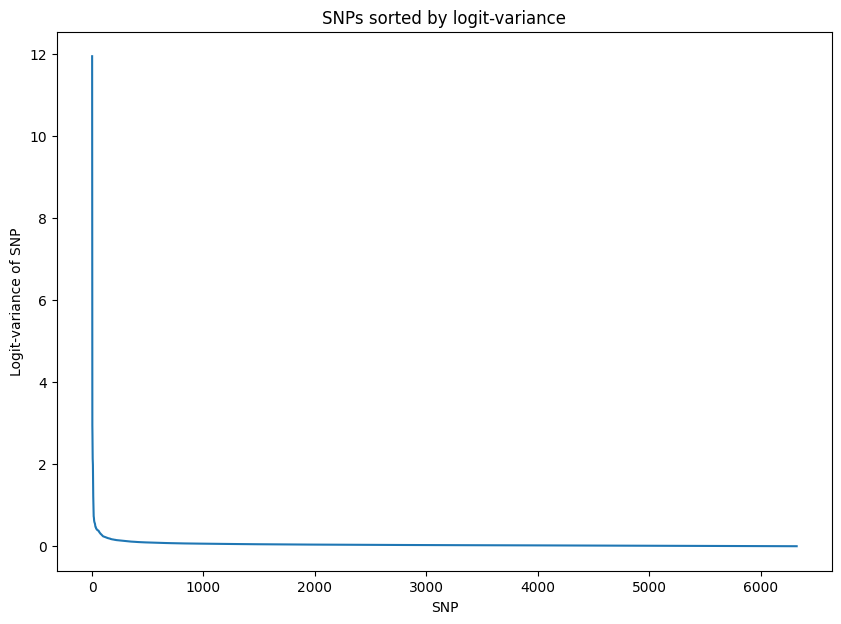

3 cells have 0 observed SNPs will be skipped.
Imputing allele frequency using k-nearest neighbouring cells.


/nobackup2/users/kevin/conda_envs/test_SNPmanifold_ST/lib/python3.8/site-packages/SNPmanifold/utils_tools.py:312: RuntimeWarning: Mean of empty slice
  pair_binomial_distance[w, :] = np.nanmean(cell_distance, 1)


Finish filtering low-quality data, 2803 cells and 77 SNPs will be used for downstream analysis.
Start training VAE.
Epoch[10/2000], Cost: 20.527843
Epoch[20/2000], Cost: 13.451486
Epoch[30/2000], Cost: 9.227264
Epoch[40/2000], Cost: 6.689144
Epoch[50/2000], Cost: 5.292871
Epoch[60/2000], Cost: 4.553628
Epoch[70/2000], Cost: 4.161243
Epoch[80/2000], Cost: 3.933676
Epoch[90/2000], Cost: 3.786904
Epoch[100/2000], Cost: 3.692537
Epoch[200/2000], Cost: 3.323795
Epoch[300/2000], Cost: 3.188996
Epoch[400/2000], Cost: 3.117281
Epoch[500/2000], Cost: 3.070997
Epoch[600/2000], Cost: 3.034109
Epoch[700/2000], Cost: 3.001577
Epoch[800/2000], Cost: 2.974462
Epoch[900/2000], Cost: 2.951901
Epoch[1000/2000], Cost: 2.934652
Epoch[1100/2000], Cost: 2.921260
Epoch[1200/2000], Cost: 2.910170
Epoch[1300/2000], Cost: 2.900451
Epoch[1400/2000], Cost: 2.891239
Epoch[1500/2000], Cost: 2.882526
Epoch[1600/2000], Cost: 2.873942
Epoch[1700/2000], Cost: 2.865527
Epoch[1800/2000], Cost: 2.856972
Epoch[1900/2000], 

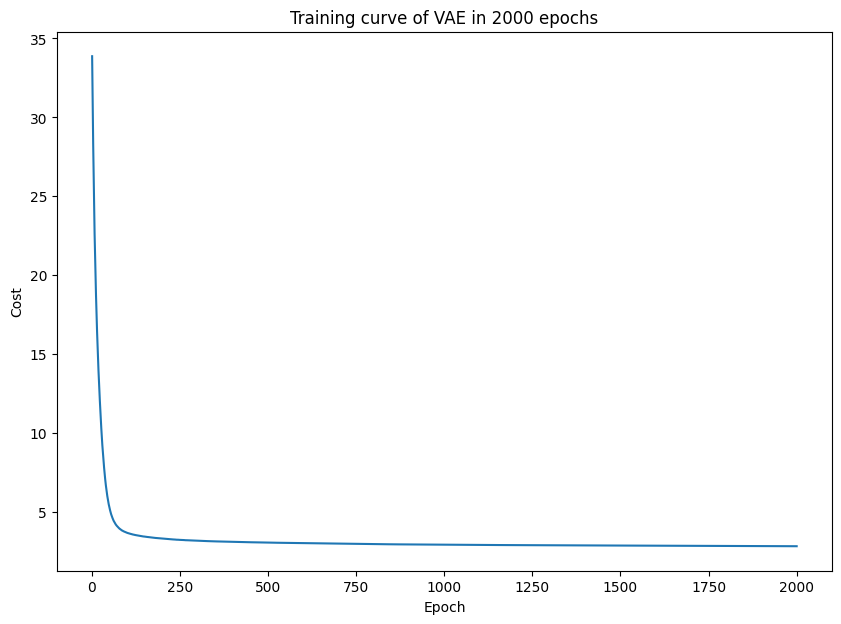

Start learning PCA and UMAP of latent space in VAE.
Finish learning, PCA and UMAP of latent space will be shown below.


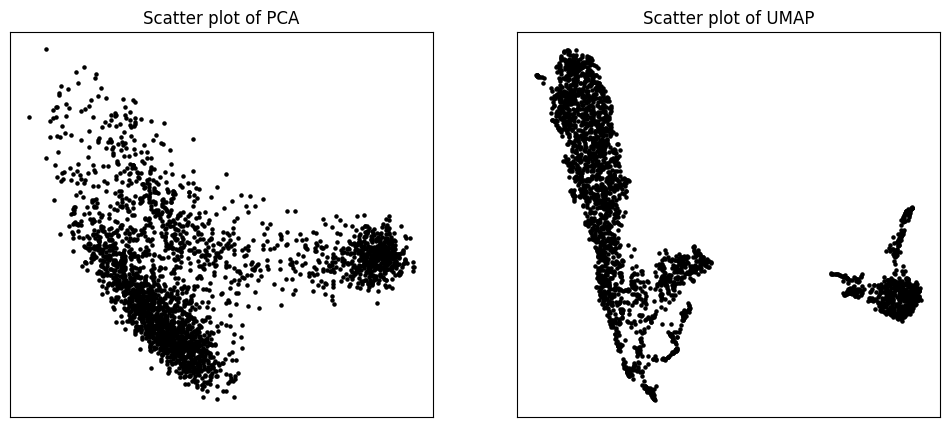

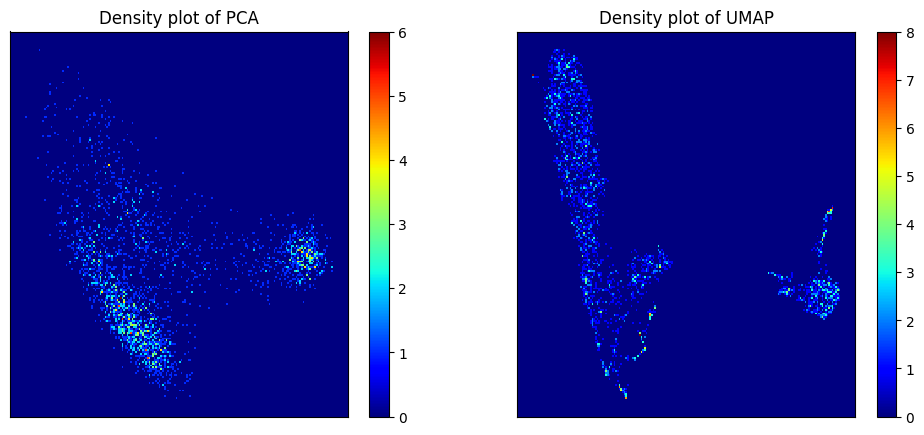

Start clustering.
Finish clustering.
PCA and UMAP of individual clusters will be shown below.


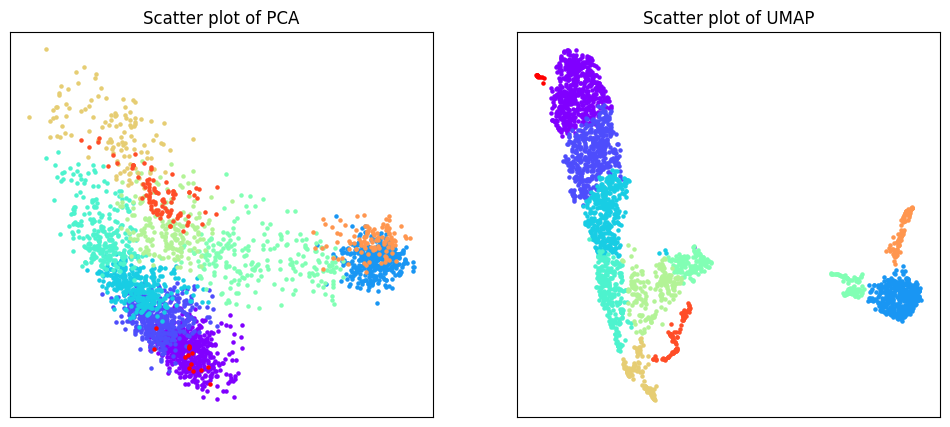

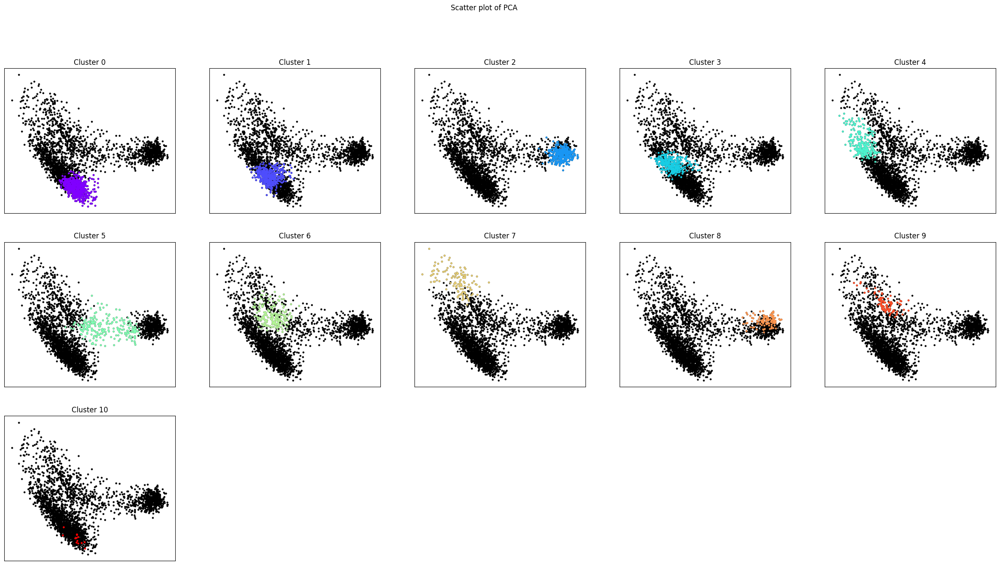

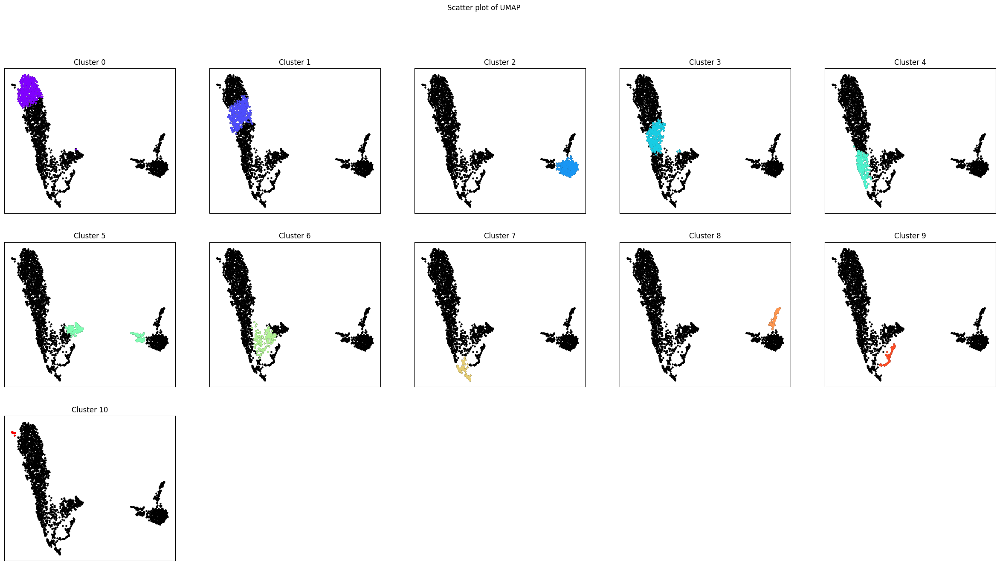

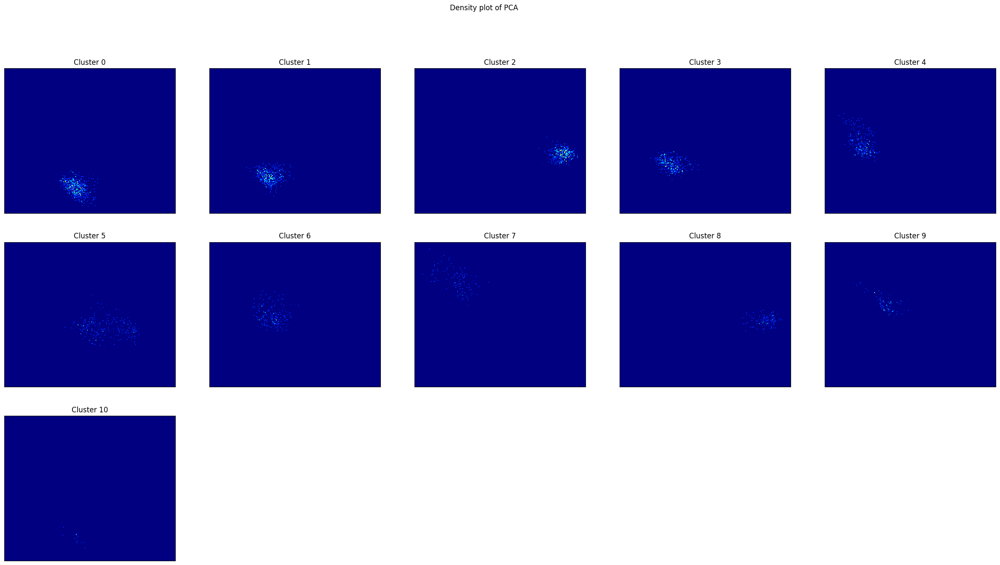

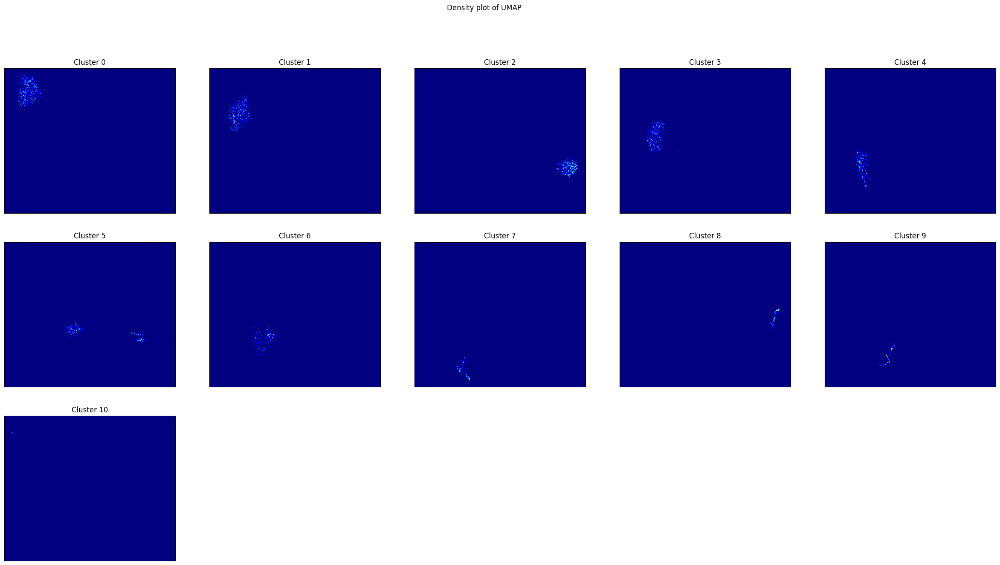

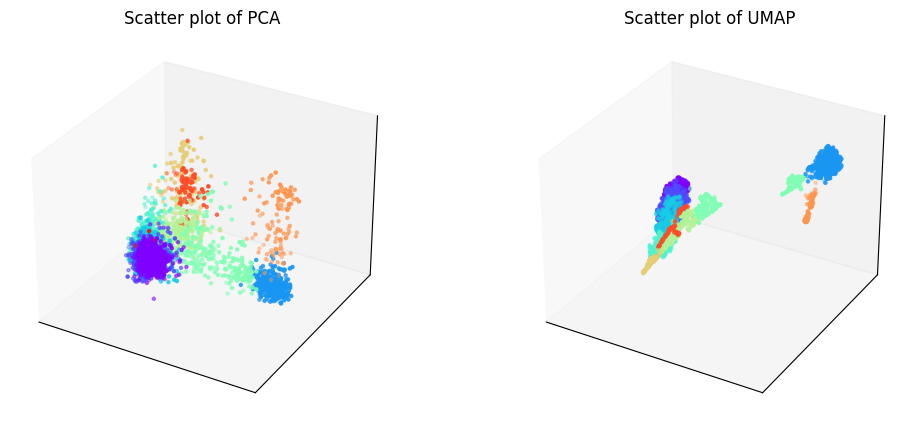

Phylogenetic tree in latent space will be shown below.


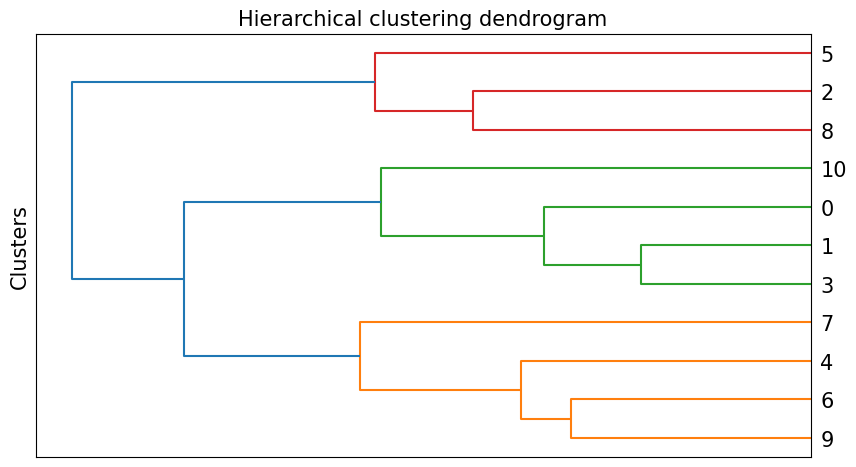

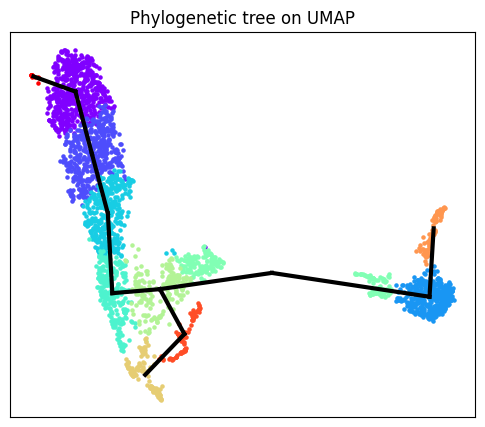

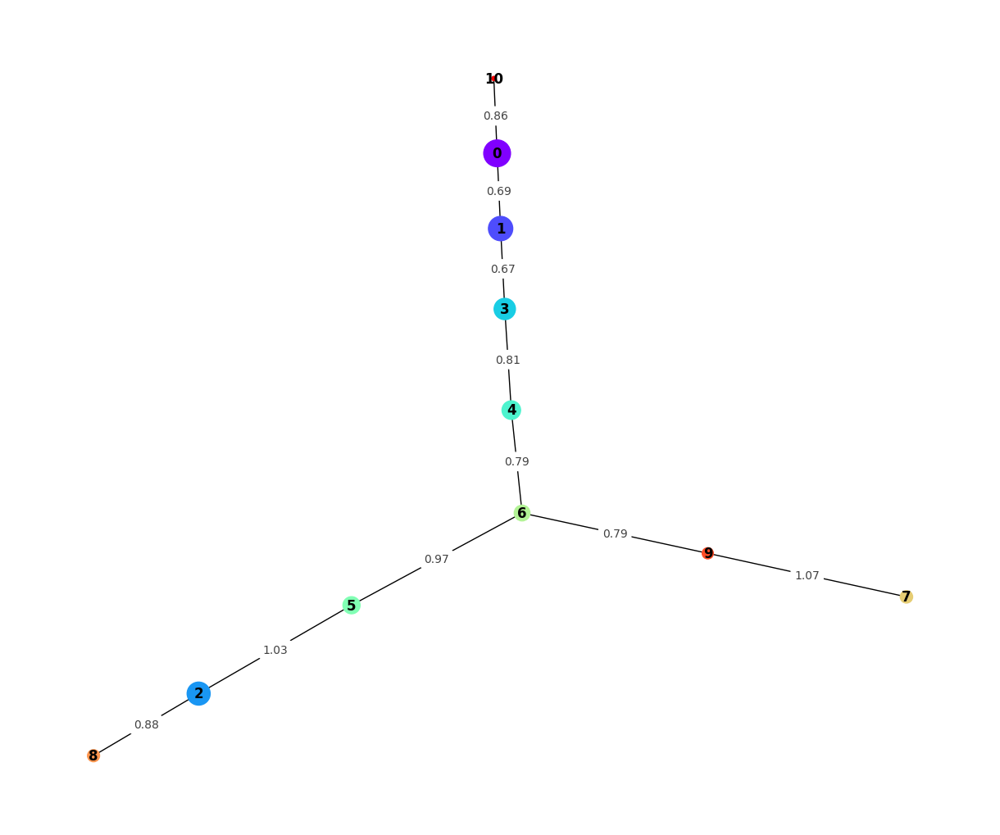

/nobackup2/users/kevin/conda_envs/test_SNPmanifold_ST/lib/python3.8/site-packages/SNPmanifold/utils_tools.py:1905: RuntimeWarning: invalid value encountered in true_divide
  SNP_cluster_AF_filtered_missing_to_nan[m, :] = np.nanmean((self.AD_filtered / self.DP_filtered)[clusters[m], :], 0)


SNP-allelic ratios of 2803 cells and 50 SNPs will be shown below.


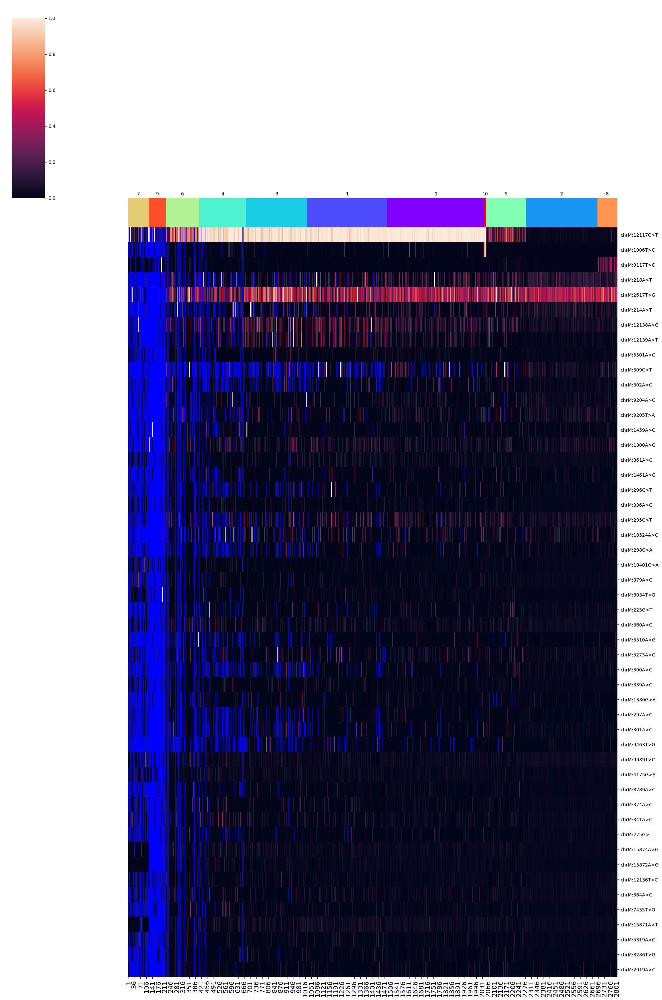

SNPs sorted by lowest p-value will be shown below


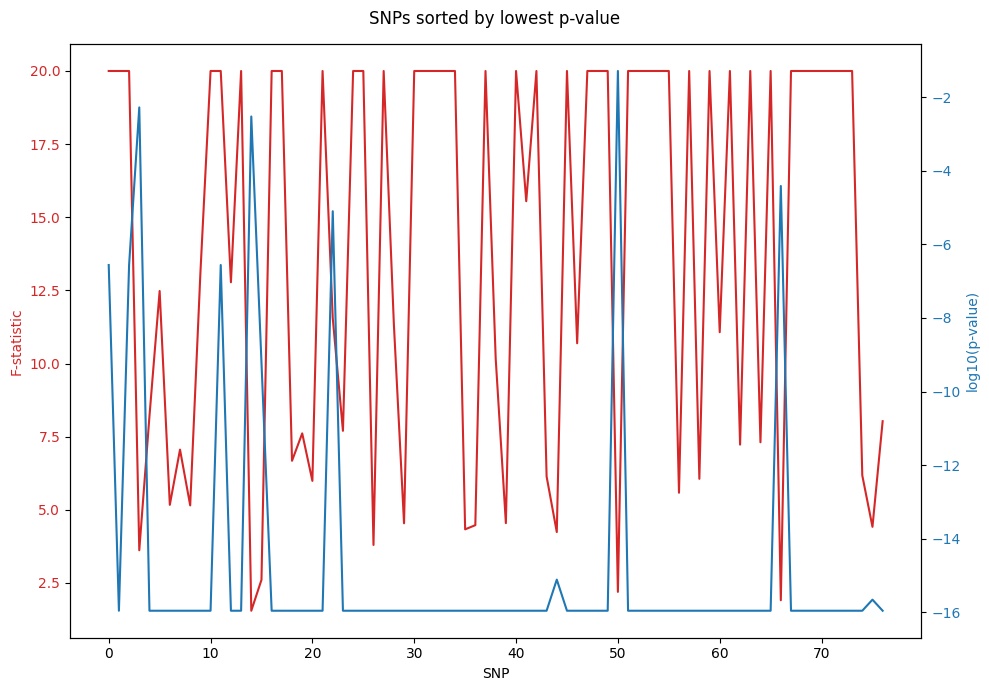

In [1]:
# This demo dataset is 10x Visium from https://github.com/HoiManC/Spatial-MT-SNV.
# Import SNPmanifold and create an object of the class SNP_VAE.
# Run 1. filtering, 2. training, 3. clustering, 4. phylogeny in order.
# Each step can rerun sperately without reruning prior steps.

import SNPmanifold

# SNPmanifold_model = SNPmanifold.SNP_VAE(path = "../../../../CSP_output") <- output path of cellSNP-lite
# SNPmanifold_model = SNPmanifold.SNP_VAE(AD = "cellSNP.tag.AD.mtx", DP = "cellSNP.tag.DP.mtx", VCF = "cellSNP.base.vcf.gz", cell_name = 'optional_cell_name.tsv')
# SNPmanifold_model = SNPmanifold.SNP_VAE(AD = "cellSNP.tag.AD.mtx", DP = "cellSNP.tag.DP.mtx", variant_name = "variant_name.tsv", cell_name = 'optional_cell_name.tsv'))

SNPmanifold_model = SNPmanifold.SNP_VAE(path = '/home/kevin/storage_kevin/prostate_visium/prostate_P1_H2_5_visium/CSP_mito', SNPread = "unnormalized", missing_value = 'KNN', UMI_correction = 'positive')
SNPmanifold_model.filtering(cell_SNPread_threshold = 500, SNP_DPmean_threshold = 5, SNP_logit_var_threshold = 0.3) # custom cutoffs, usually set at turning points or assumptions, set all zeros if you do not want any filtering.
SNPmanifold_model.training(is_cuda = False) # set is_cuda to False if you use CPU.
SNPmanifold_model.clustering() # the default algorithm is leiden (resolution = 1) from scanpy, set algorithm = "kmeans_full" if you want k-means
SNPmanifold_model.phylogeny() # you can set cluster_no if you want a specific number of clusters (for k-means only)

PCA and UMAP of individual clusters will be shown below.


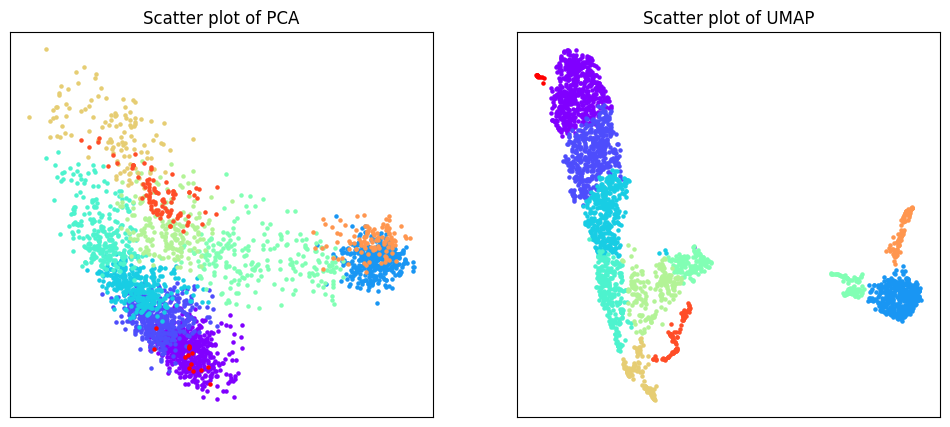

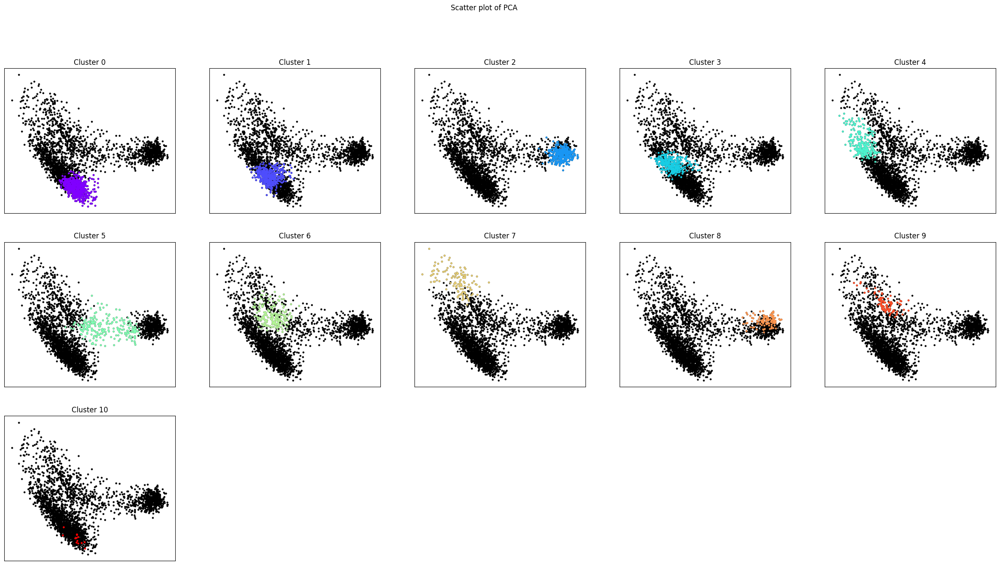

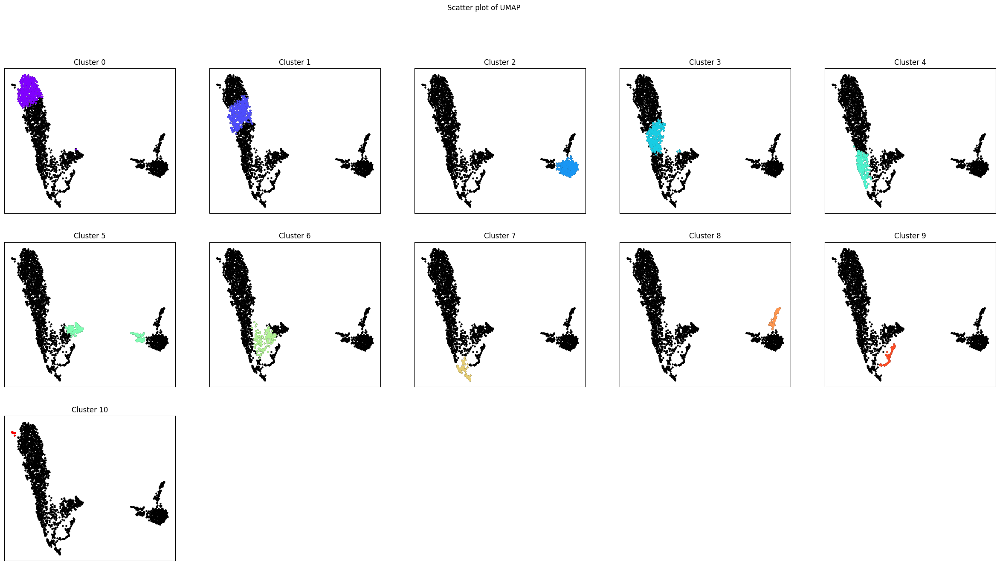

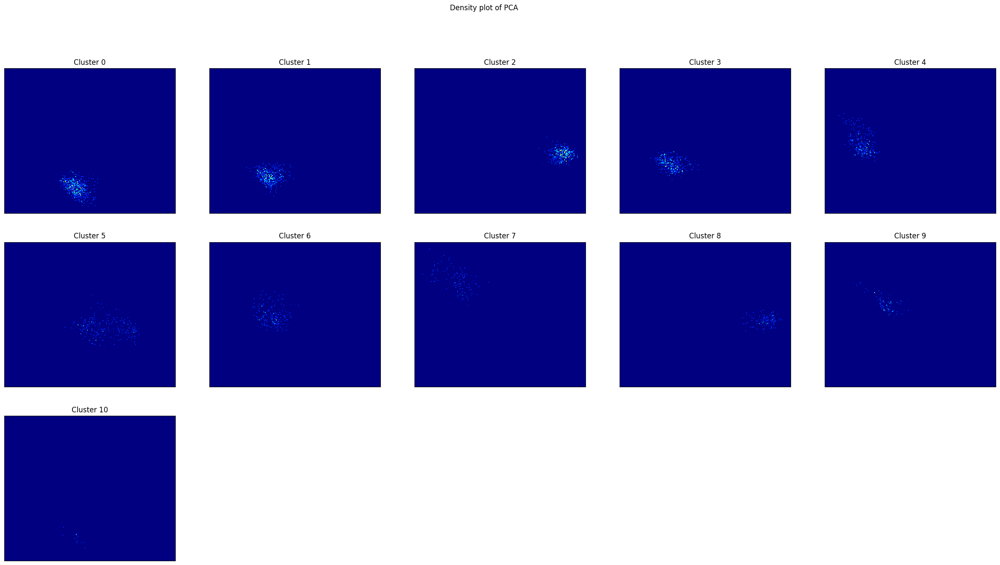

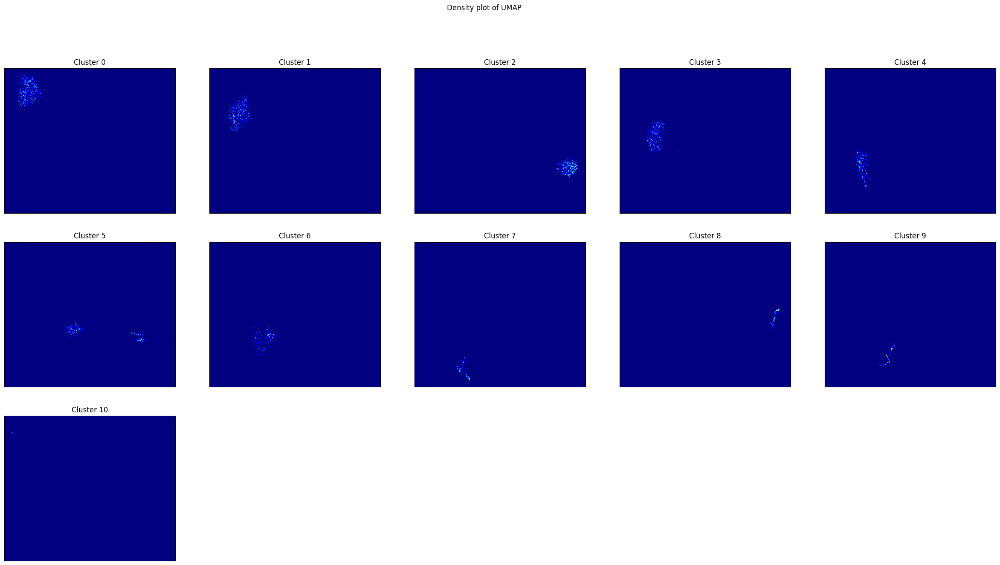

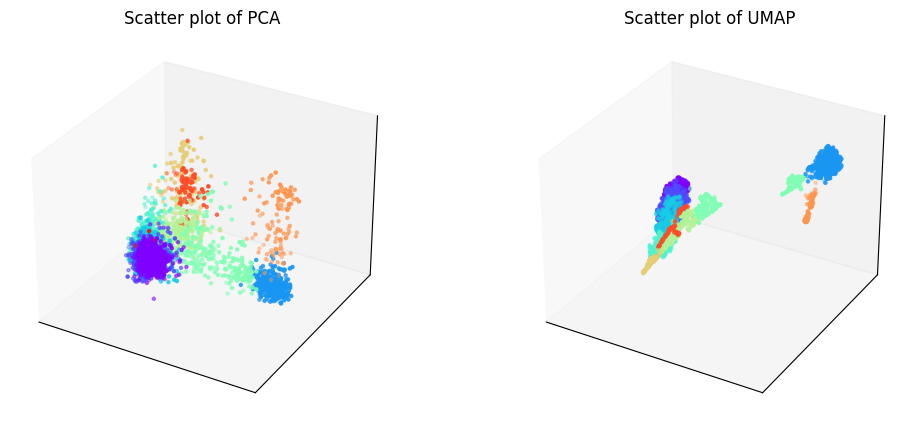

Phylogenetic tree in latent space will be shown below.


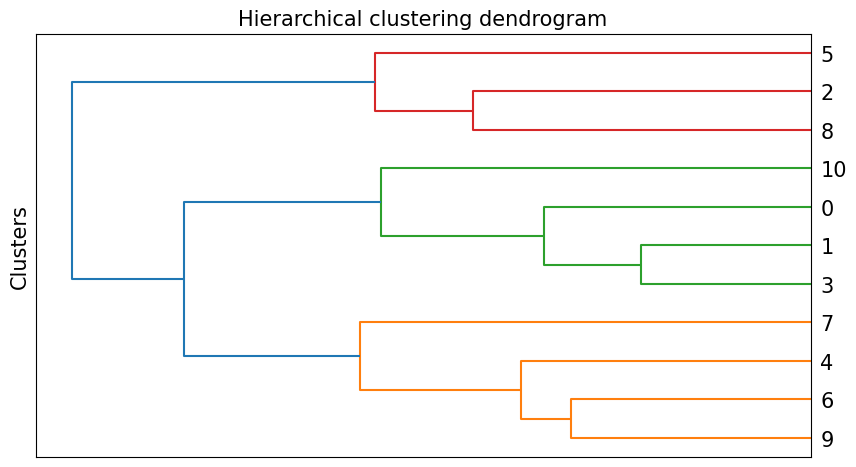

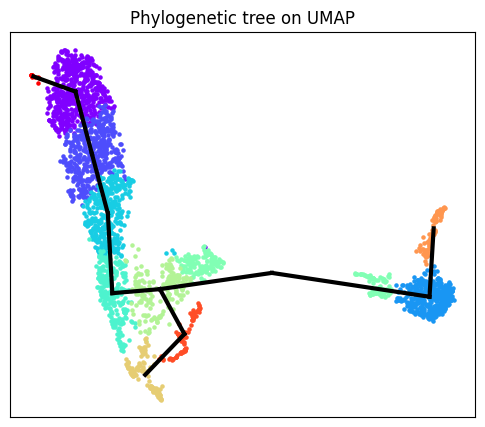

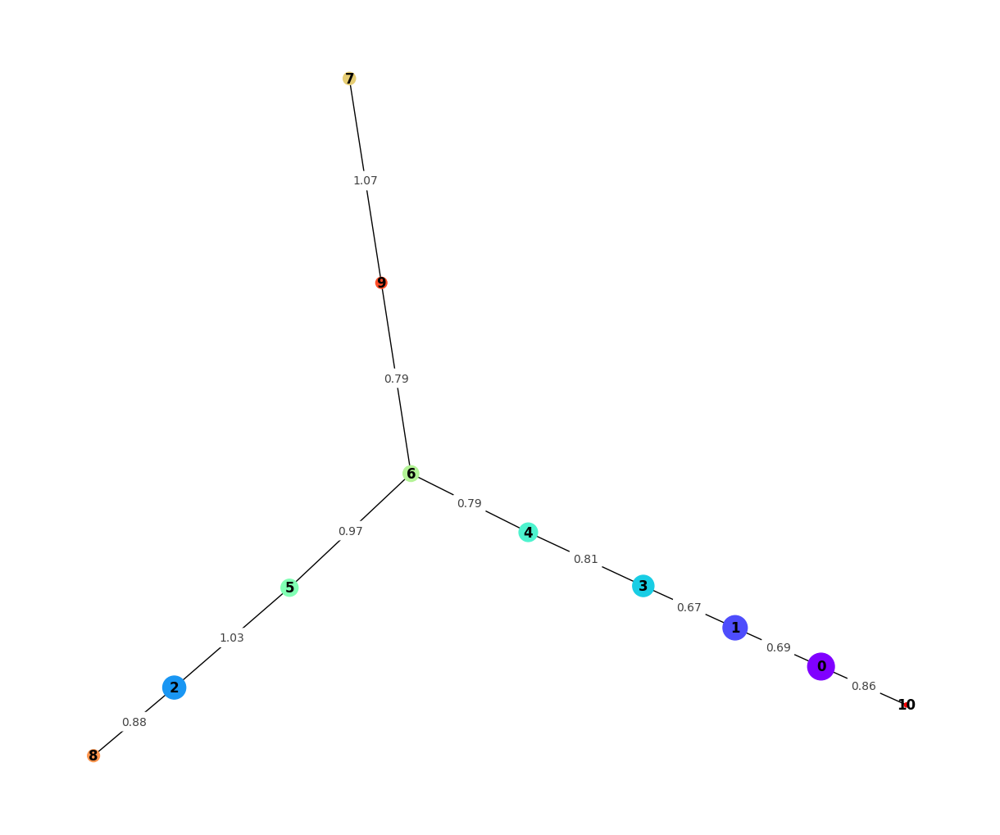

SNP-allelic ratios of 2803 cells and 10 SNPs will be shown below.


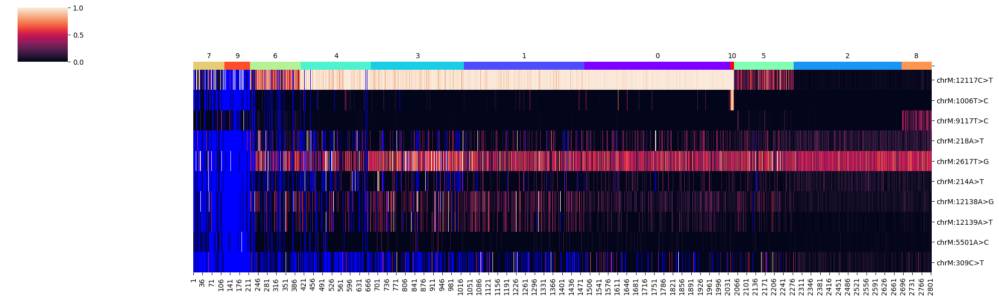

SNPs sorted by lowest p-value will be shown below


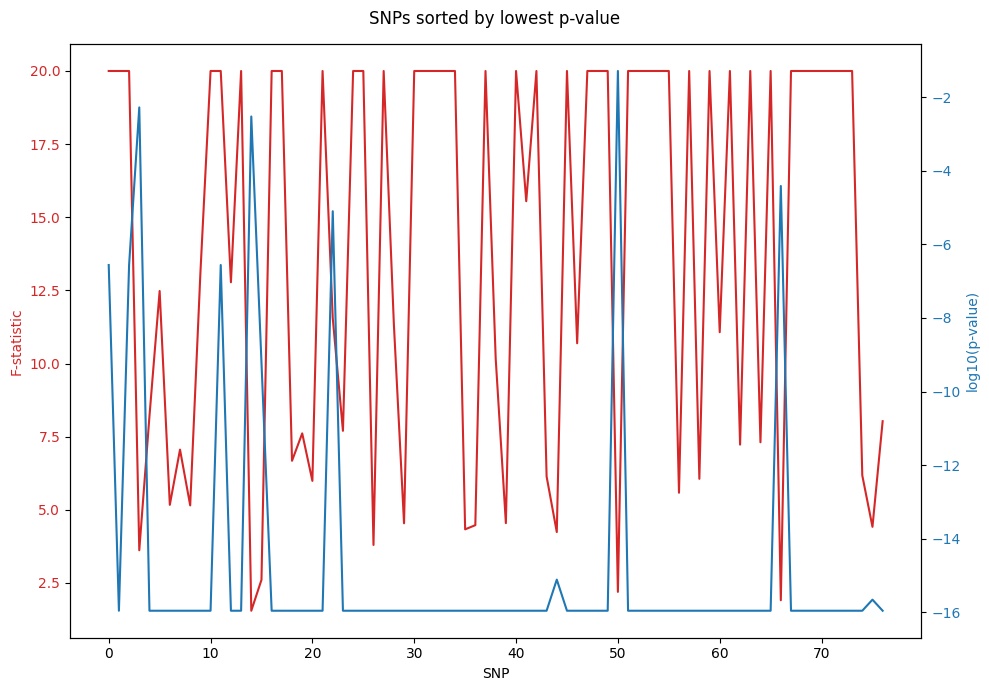

In [11]:
# Re-display figures in higher dpi

# SNPmanifold_model.filtering_summary(dpi = 300)
# SNPmanifold_model.training_summary(dpi = 300)
# SNPmanifold_model.clustering_summary(dpi = 300)

SNPmanifold_model.phylogeny_summary(SNP_no = 10, dpi = 100)

/nobackup2/users/kevin/conda_envs/test_SNPmanifold_ST/lib/python3.8/site-packages/anndata/_core/anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


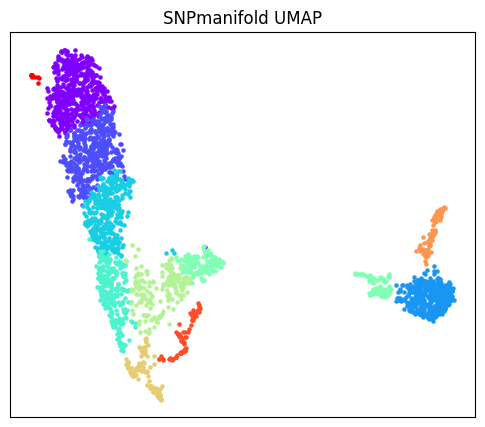

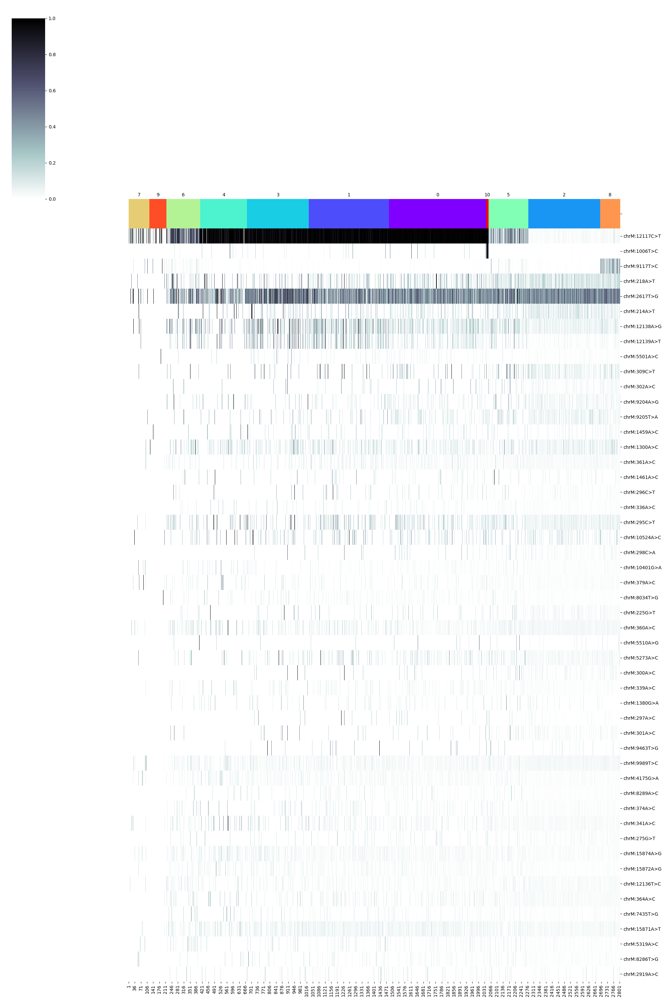

In [12]:
# Save results into h5ad and plots

import matplotlib as mpl

SNPmanifold_model.save_h5ad('results.h5ad')
SNPmanifold_model.save_umap_plot('umap.pdf', dpi = 100)
SNPmanifold_model.save_AF_plot('AF.pdf', cmap_heatmap = mpl.colormaps['bone_r'], bad_color = 'white', dpi = 100)

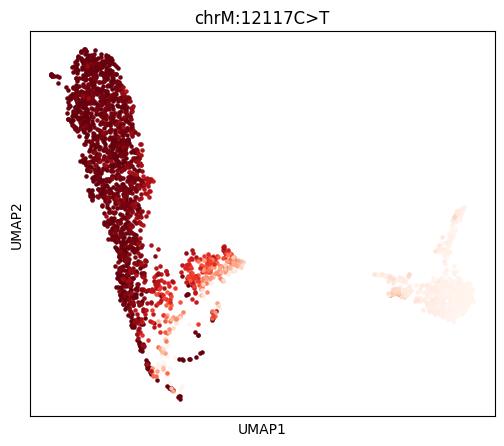

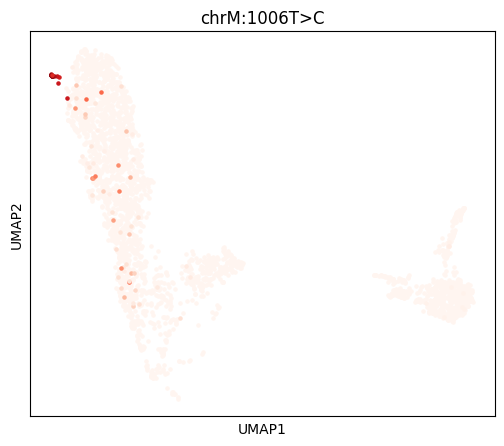

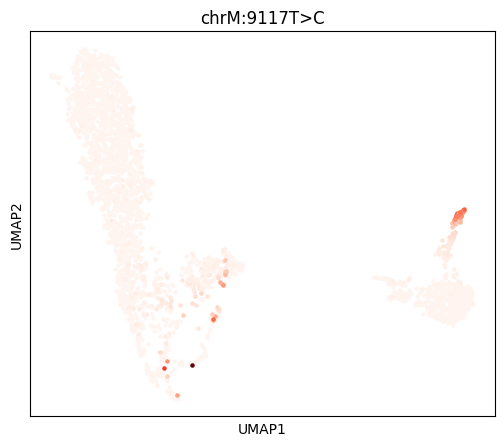

In [15]:
# Visualize frequency of particular SNPs on embeddings learnt by SNPmanifold

SNPmanifold_model.AF_scatter("chrM:12117C>T", dpi = 100)
SNPmanifold_model.AF_scatter("chrM:1006T>C", dpi = 100)
SNPmanifold_model.AF_scatter("chrM:9117T>C", dpi = 100)

In [4]:
import squidpy as sq
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

adata_vis = sq.read.visium('/home/kevin/storage_kevin/prostate_visium/prostate_P1_H2_5_visium')

/nobackup2/users/kevin/conda_envs/test_SNPmanifold_ST/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/nobackup2/users/kevin/conda_envs/test_SNPmanifold_ST/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [5]:
metadata = pd.read_csv('/home/kevin/storage_kevin/prostate_visium/prostate_P1_H2_5_visium/P1_H2_5_Final_Consensus_Annotations.csv')
metadata.index = metadata['cell']

adata_vis.obs = adata_vis.obs.join(metadata, how="left")

/nobackup2/users/kevin/conda_envs/test_SNPmanifold_ST/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


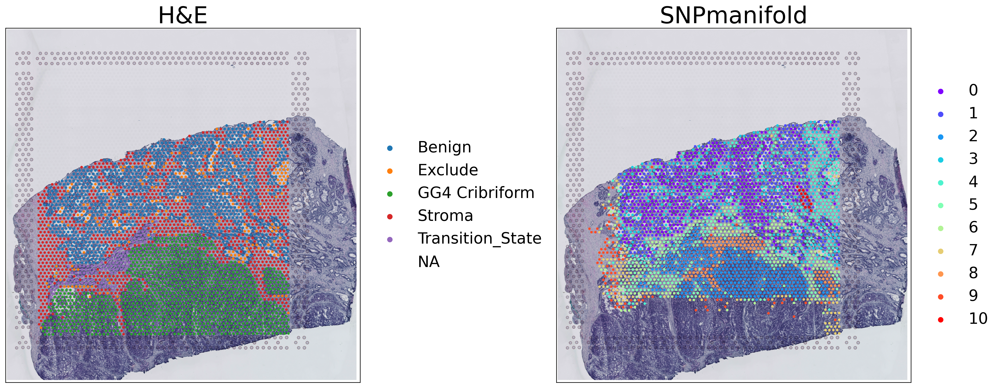

In [6]:
# adata_vis.uns.pop('SNPmanifold_colors')

adata_vis.obs['SNPmanifold'] = 'NA'
adata_vis.obs.loc[SNPmanifold_model.cell_filter, 'SNPmanifold'] = SNPmanifold_model.assigned_label.astype(str)
adata_vis.obs['SNPmanifold'] = adata_vis.obs['SNPmanifold'].astype('category')

adata_vis_noNA = adata_vis[adata_vis.obs['SNPmanifold'] != 'NA'].copy()
adata_vis_noNA.obs['SNPmanifold'] = adata_vis_noNA.obs['SNPmanifold'].cat.reorder_categories(np.arange(SNPmanifold_model.cluster_no).astype(str))

fig, axs = plt.subplots(1, 2, figsize=(18, 12))
sq.pl.spatial_scatter(adata_vis, color = 'hist_anno', ax = axs[0], legend_fontsize = 20)
sq.pl.spatial_scatter(adata_vis_noNA, color = 'SNPmanifold', ax = axs[1], palette = 'rainbow', legend_fontsize = 20)

axs[0].set_title('H&E', fontsize = 30)
axs[1].set_title('SNPmanifold', fontsize = 30)

axs[0].set_xlabel('')
axs[0].set_ylabel('')
axs[1].set_xlabel('')
axs[1].set_ylabel('')

fig.set_dpi(300)

plt.tight_layout()
plt.show()